# Ecuaciones diferenciales ordinarias II
## Runge–Kutta de cuarto orden y `solve_ivp`


### Objetivos
- Implementar RK4 desde cero.
- Comparar con una solución exacta.
- Estudiar el efecto del tamaño de paso.
- Resolver EDO con `scipy.integrate.solve_ivp`.
- Resolver un problema físico.
- Introducir sistemas de EDO.

## 1. Librerías

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

plt.rcParams["figure.figsize"] = (8, 5)


## 2. Implementación de RK4

Para

$$
y'=f(t,y)$$

calculamos

$$
k_1=f(t_n,y_n),
$$

$$
k_2=f\left(t_n+\frac h2,y_n+\frac h2k_1\right),
$$

$$
k_3=f\left(t_n+\frac h2,y_n+\frac h2k_2\right),
$$

$$
k_4=f(t_n+h,y_n+hk_3),
$$

y

$$
y_{n+1}=y_n+\frac h6(k_1+2k_2+2k_3+k_4).
$$

In [2]:
def rk4(f, t0, tf, y0, h):
    """Resuelve una EDO escalar con RK4 de paso fijo."""
    t = np.arange(t0, tf + h, h)
    y = np.zeros(len(t), dtype=float)
    y[0] = y0

    for n in range(len(t) - 1):
        k1 = f(t[n], y[n])
        k2 = f(t[n] + h/2, y[n] + h*k1/2)
        k3 = f(t[n] + h/2, y[n] + h*k2/2)
        k4 = f(t[n] + h, y[n] + h*k3)

        y[n+1] = y[n] + h*(k1 + 2*k2 + 2*k3 + k4)/6

    return t, y


## 3. Ejemplo resuelto 1: decaimiento exponencial

$$
\frac{dy}{dt}=-2y,\qquad y(0)=1.
$$

La solución exacta es

$$
y(t)=e^{-2t}.
$$

In [3]:
def f_exp(t, y):
    return -2*y

t, y_rk4 = rk4(f_exp, 0, 5, 1, 0.1)
y_exacta = np.exp(-2*t)

error = np.abs(y_exacta - y_rk4)

print("Error máximo =", np.max(error))


Error máximo = 5.79695385960477e-06


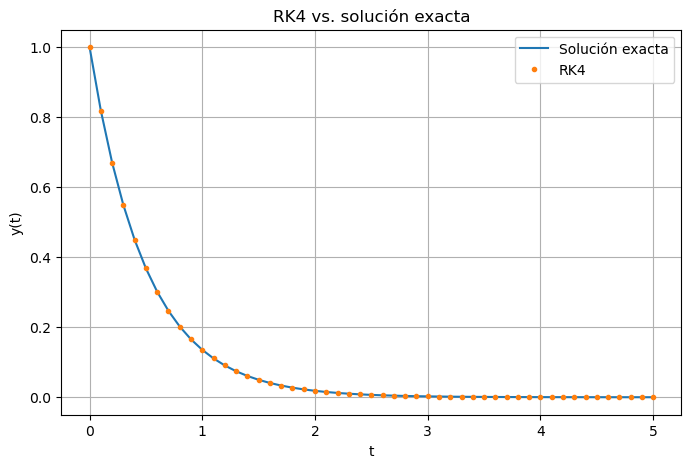

In [4]:
plt.plot(t, y_exacta, label="Solución exacta")
plt.plot(t, y_rk4, "o", markersize=3, label="RK4")

plt.xlabel("t")
plt.ylabel("y(t)")
plt.title("RK4 vs. solución exacta")
plt.grid()
plt.legend()
plt.show()


## 4. Estudio del tamaño de paso

Como RK4 es de cuarto orden, esperamos aproximadamente

$$
E(h)\propto h^4.
$$

Vamos a comprobarlo experimentalmente.

In [5]:
hs = [0.5, 0.1, 0.05, 0.01]
errores = []

for h in hs:
    t_h, y_h = rk4(f_exp, 0, 5, 1, h)
    exacta_h = np.exp(-2*t_h)
    errores.append(np.max(np.abs(exacta_h - y_h)))

for h, e in zip(hs, errores):
    print(f"h = {h:6.3f}   error máximo = {e:.6e}")


h =  0.500   error máximo = 7.120559e-03
h =  0.100   error máximo = 5.796954e-06
h =  0.050   error máximo = 3.332411e-07
h =  0.010   error máximo = 4.987514e-10


In [6]:
print("Razones E(h)/E(h/2) cuando los pasos son comparables:")

for i in range(len(hs) - 1):
    if np.isclose(hs[i+1], hs[i]/2):
        print(hs[i], "/", hs[i+1], "=", errores[i]/errores[i+1])


Razones E(h)/E(h/2) cuando los pasos son comparables:
0.1 / 0.05 = 17.395677254607946


## 5. Solución con `solve_ivp`

La estructura básica es:

```python
sol = solve_ivp(fun, t_span, y0)
```

Usaremos `t_eval` para solicitar la solución en puntos específicos.

In [8]:
t_eval = np.linspace(0, 5, 100)

sol = solve_ivp(
    f_exp,
    (0, 5),
    [1],
    t_eval=t_eval,
    method="RK45"
)

print("Número de puntos solicitados:", len(sol.t))
print("Primer valor:", sol.y[0, 0])
print("Último valor:", sol.y[0, -1])


Número de puntos solicitados: 100
Primer valor: 1.0
Último valor: 4.5723789415634636e-05


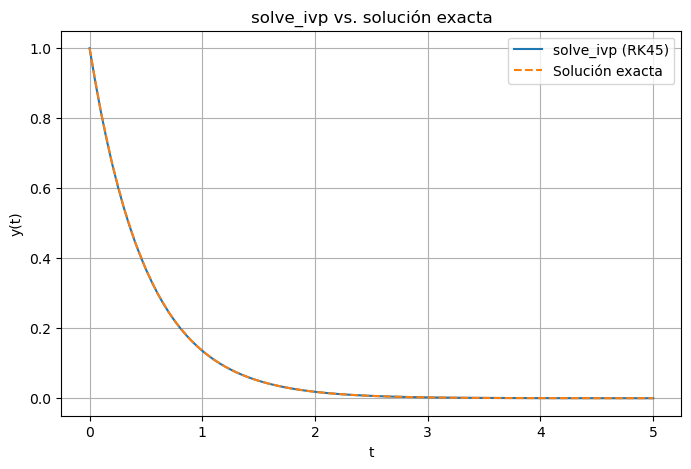

In [9]:
plt.plot(sol.t, sol.y[0], label="solve_ivp (RK45)")
plt.plot(t, y_exacta, "--", label="Solución exacta")

plt.xlabel("t")
plt.ylabel("y(t)")
plt.title("solve_ivp vs. solución exacta")
plt.grid()
plt.legend()
plt.show()


## 6. Comparación directa

Para comparar soluciones es importante evaluarlas en los mismos tiempos. Usaremos los puntos de `t_eval` para RK4 y `solve_ivp`.

In [ ]:
t_eval = np.linspace(0, 5, 101)
h = t_eval[1] - t_eval[0]

t_rk4, y_rk4_eval = rk4(f_exp, 0, 5, 1, h)

sol = solve_ivp(
    f_exp,
    (0, 5),
    [1],
    t_eval=t_eval,
    method="RK45"
)

error_entre_metodos = np.abs(y_rk4_eval - sol.y[0])

print("Error máximo entre RK4 y solve_ivp:",
      np.max(error_entre_metodos))


## 7. Ejemplo resuelto 2: caída con resistencia lineal

Modelo:

$$
m\frac{dv}{dt}=mg-cv.
$$

Por tanto,

$$
\frac{dv}{dt}=g-\frac{c}{m}v.
$$

Parámetros:

$$
m=2\;\mathrm{kg},\quad
c=0.5\;\mathrm{kg/s},\quad
g=9.81\;\mathrm{m/s^2}.
$$

La velocidad terminal es

$$
v_T=\frac{mg}{c}.
$$

In [10]:
m = 2.0
c = 0.5
g = 9.81

v_terminal = m*g/c
print("Velocidad terminal =", v_terminal, "m/s")

def dvdt(t, v):
    return g - (c/m)*v


Velocidad terminal = 39.24 m/s


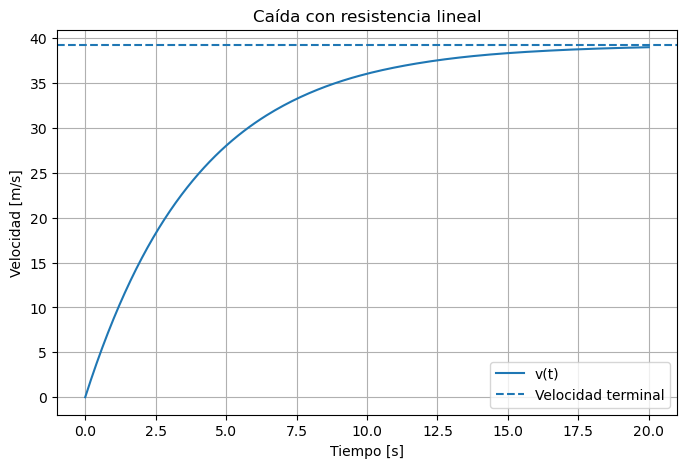

In [11]:
t_eval = np.linspace(0, 20, 200)

sol_caida = solve_ivp(
    dvdt,
    (0, 20),
    [0],
    t_eval=t_eval,
    method="RK45"
)

plt.plot(sol_caida.t, sol_caida.y[0], label="v(t)")
plt.axhline(v_terminal, linestyle="--",
            label="Velocidad terminal")

plt.xlabel("Tiempo [s]")
plt.ylabel("Velocidad [m/s]")
plt.title("Caída con resistencia lineal")
plt.grid()
plt.legend()
plt.show()


### Preguntas de interpretación

1. ¿Por qué la velocidad comienza aumentando rápidamente?
2. ¿Por qué la pendiente de la curva disminuye?
3. ¿Qué representa la velocidad terminal?
4. ¿Qué ocurriría si aumentamos `c`?
5. ¿Qué ocurriría si aumentamos `m`?

## 8. Sistemas de EDO: oscilador armónico

Partimos de

$$
x''+\omega^2x=0.
$$

Definimos

$$
v=x'.
$$

Entonces:

$$
x'=v,\qquad v'=-\omega^2x.
$$

El estado será

$$
y=
\begin{pmatrix}
x\\
v
\end{pmatrix}.
$$

In [12]:
omega = 2.0

def oscilador(t, y):
    x, v = y
    dxdt = v
    dvdt = -(omega**2)*x
    return [dxdt, dvdt]

t_eval = np.linspace(0, 10, 500)

sol_osc = solve_ivp(
    oscilador,
    (0, 10),
    [1, 0],
    t_eval=t_eval,
    method="RK45"
)


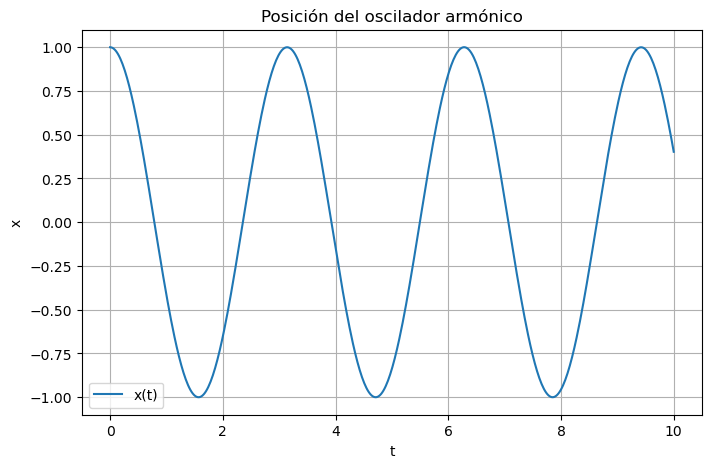

In [13]:
x = sol_osc.y[0]
v = sol_osc.y[1]

plt.plot(sol_osc.t, x, label="x(t)")
plt.xlabel("t")
plt.ylabel("x")
plt.title("Posición del oscilador armónico")
plt.grid()
plt.legend()
plt.show()


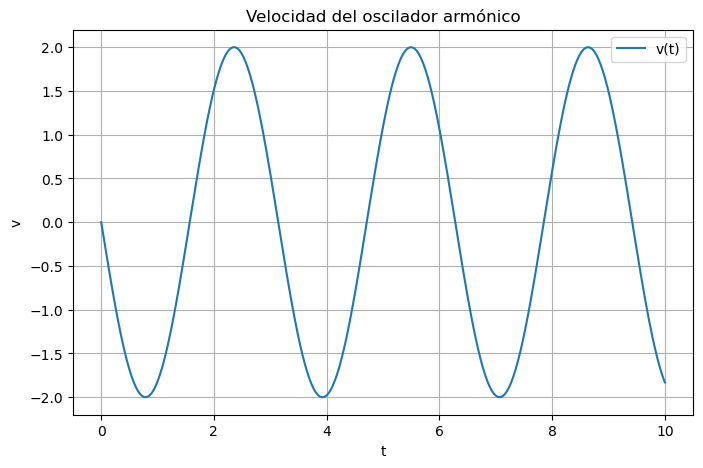

In [14]:
plt.plot(sol_osc.t, v, label="v(t)")
plt.xlabel("t")
plt.ylabel("v")
plt.title("Velocidad del oscilador armónico")
plt.grid()
plt.legend()
plt.show()


## 9. Comparación con la solución exacta

Para

$$
x(0)=1,\qquad v(0)=0,
$$

la solución exacta es

$$
x(t)=\cos(\omega t).
$$

Calculamos el error máximo.

Error máximo en x(t) = 0.0054552146047257


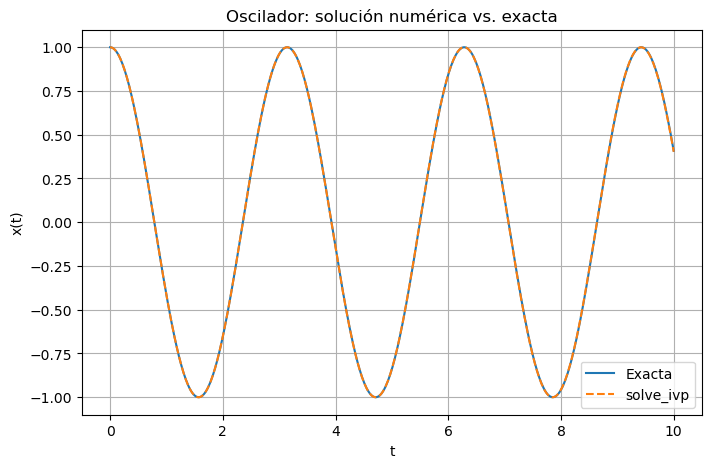

In [15]:
x_exacta = np.cos(omega*t_eval)
error_x = np.abs(x - x_exacta)

print("Error máximo en x(t) =", np.max(error_x))

plt.plot(t_eval, x_exacta, label="Exacta")
plt.plot(sol_osc.t, x, "--", label="solve_ivp")

plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Oscilador: solución numérica vs. exacta")
plt.grid()
plt.legend()
plt.show()


## 10. Actividad para casa

### Ejercicio 1 — Ecuación logística

Resolver

$$
y'=y(1-y),\qquad y(0)=0.1,
$$

en \(0\leq t\leq10\).

- Implementar RK4.
- Resolver con `solve_ivp`.
- Graficar ambas soluciones.
- Compararlas en los mismos puntos.
- Calcular el error máximo.

### Ejercicio 2 — Oscilador armónico

Resolver

$$
x''+\omega^2x=0,
$$

con

$$
x(0)=1,\qquad v(0)=0,\qquad\omega=2.
$$

- Transformar a sistema de primer orden.
- Resolver con `solve_ivp`.
- Graficar \(x(t)\) y \(v(t)\).
- Comparar \(x(t)\) con \(\cos(\omega t)\).